Objective: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

Dataset: This lab utilizes the Amazon UK product dataset which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [5]:
df = pd.read_csv('C:/Users/Kinga/Desktop/lab-eda-bivariate/amz_uk_price_prediction_dataset.csv')

In [6]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


# Part 1: Analyzing Best-Seller Trends Across Product Categories 
### Objective: Understand the relationship between product categories and their best-seller status. 

## Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

## Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.

## Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [7]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
print(crosstab)

isBestSeller                    False  True 
category                                    
3D Printers                       247      1
3D Printing & Scanning           4065      2
Abrasive & Finishing Products     245      5
Action Cameras                   1696      1
Adapters                          251      3
...                               ...    ...
Wind Instruments                  243      7
Window Treatments                 234      5
Women                           17559    213
Women's Sports & Outdoor Shoes   1939     20
eBook Readers & Accessories       246      0

[296 rows x 2 columns]


In [12]:
# Calculate proportion of best-sellers in each category
crosstab['best_seller_ratio'] = crosstab[True] / (crosstab[True] + crosstab[False])

# Sort categories by best-seller ratio in descending order
sorted_crosstab = crosstab.sort_values('best_seller_ratio', ascending=False)

print(sorted_crosstab[['best_seller_ratio']])

isBestSeller                      best_seller_ratio
category                                           
Grocery                                    0.058135
Smart Home Security & Lighting             0.057692
Health & Personal Care                     0.057686
Mobile Phone Accessories                   0.042471
Power & Hand Tools                         0.035339
...                                             ...
CD, Disc & Tape Players                    0.000000
General Music-Making Accessories           0.000000
Snowboard Boots                            0.000000
Boxes & Organisers                         0.000000
eBook Readers & Accessories                0.000000

[296 rows x 1 columns]


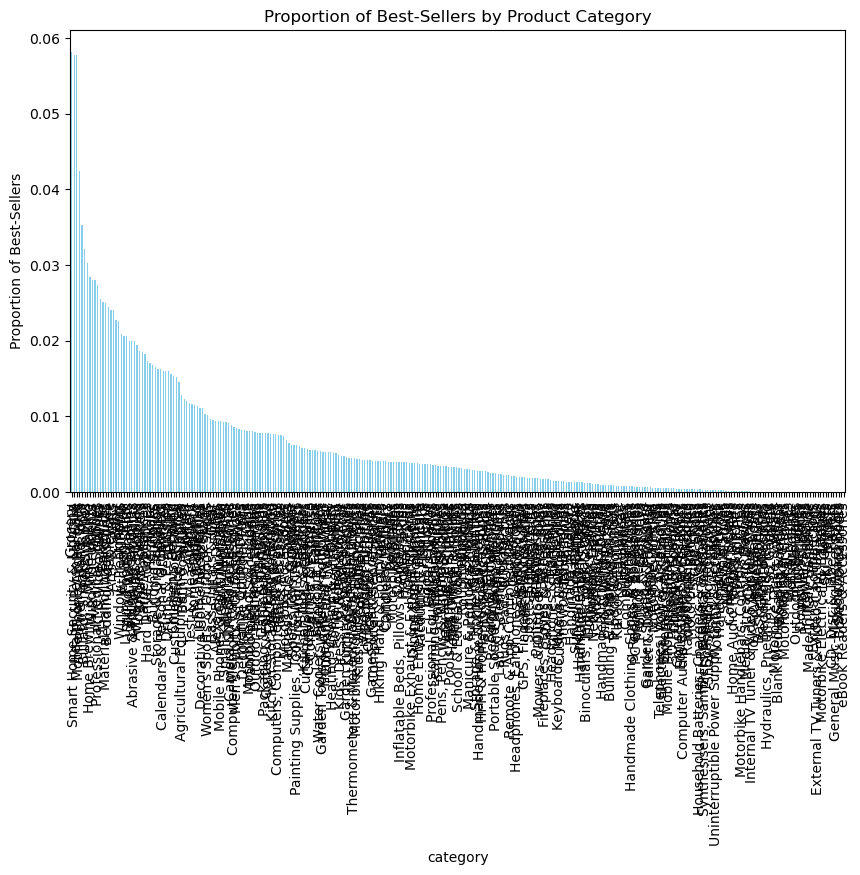

In [10]:
sorted_crosstab['best_seller_ratio'].plot(kind='bar', figsize=(10,6), color='skyblue')
plt.ylabel('Proportion of Best-Sellers')
plt.title('Proportion of Best-Sellers by Product Category')
plt.show()

In [13]:
# Sort categories by best-seller ratio in descending order and take top 50
top50_categories = crosstab.sort_values('best_seller_ratio', ascending=False).head(50)

print(top50_categories[['best_seller_ratio']])

isBestSeller                       best_seller_ratio
category                                            
Grocery                                     0.058135
Smart Home Security & Lighting              0.057692
Health & Personal Care                      0.057686
Mobile Phone Accessories                    0.042471
Power & Hand Tools                          0.035339
Billiard, Snooker & Pool                    0.032129
Pet Supplies                                0.030200
Home Brewing & Wine Making                  0.028455
Wind Instruments                            0.028000
Mirrors                                     0.028000
Professional Medical Supplies               0.027344
PC & Video Games                            0.025466
Bakeware                                    0.025105
Material Handling Products                  0.025000
Bedding Accessories                         0.024390
Tableware                                   0.024096
Arts & Crafts                               0.

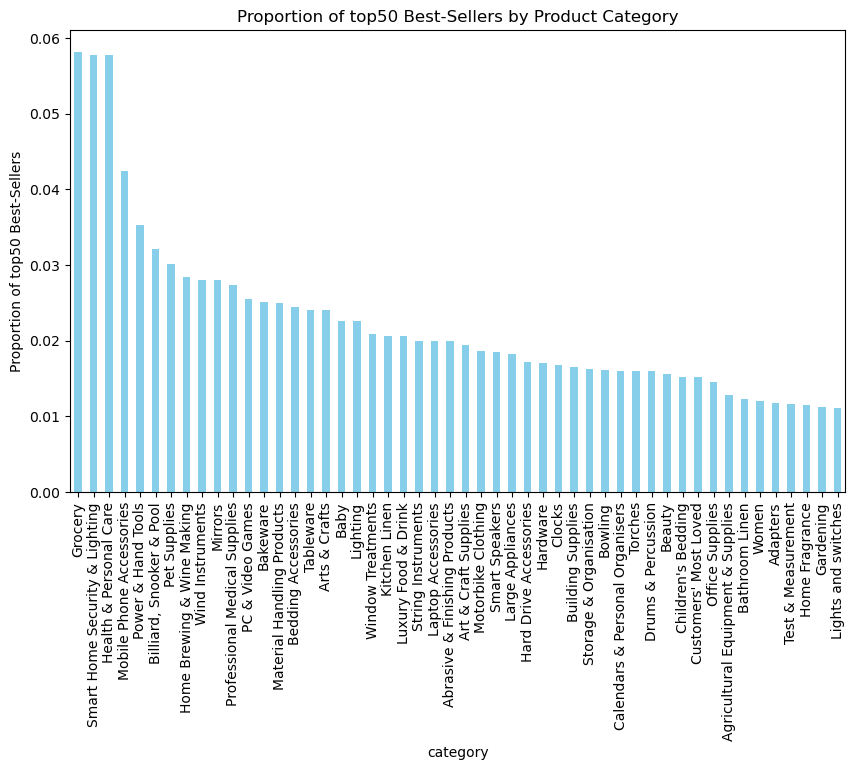

In [15]:
top50_categories['best_seller_ratio'].plot(kind='bar', figsize=(10,6), color='skyblue')
plt.ylabel('Proportion of top50 Best-Sellers')
plt.title('Proportion of top50 Best-Sellers by Product Category')
plt.show()

### Chi-square test

In [17]:
import scipy.stats as stats


In [18]:
chi2, p, dof, expected = stats.chi2_contingency(crosstab)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.5f}")

Chi-square statistic: 36684.24
Degrees of freedom: 590
P-value: 0.00000


P-value < 0.05 → reject the null hypothesis → best-seller status is not independent of category

P-value ≥ 0.05 → fail to reject → independent

### Compute Cramér's V

In [19]:
n = crosstab.sum().sum()  # total observations
cramers_v = np.sqrt(chi2 / (n * (min(crosstab.shape)-1)))

print(f"Cramér's V: {cramers_v:.3f}")

Cramér's V: 0.087


0 → no association

1 → perfect association

Values around 0.1–0.3 → weak association, 0.3–0.5 → moderate, above 0.5 → strong

In [21]:
# Calculate best-seller ratio
crosstab['best_seller_ratio'] = crosstab[True] / (crosstab[True] + crosstab[False])

# Sort by ratio
crosstab = crosstab.sort_values('best_seller_ratio', ascending=False)

# Drop the ratio column for plotting
crosstab_plot = crosstab.drop(columns='best_seller_ratio')

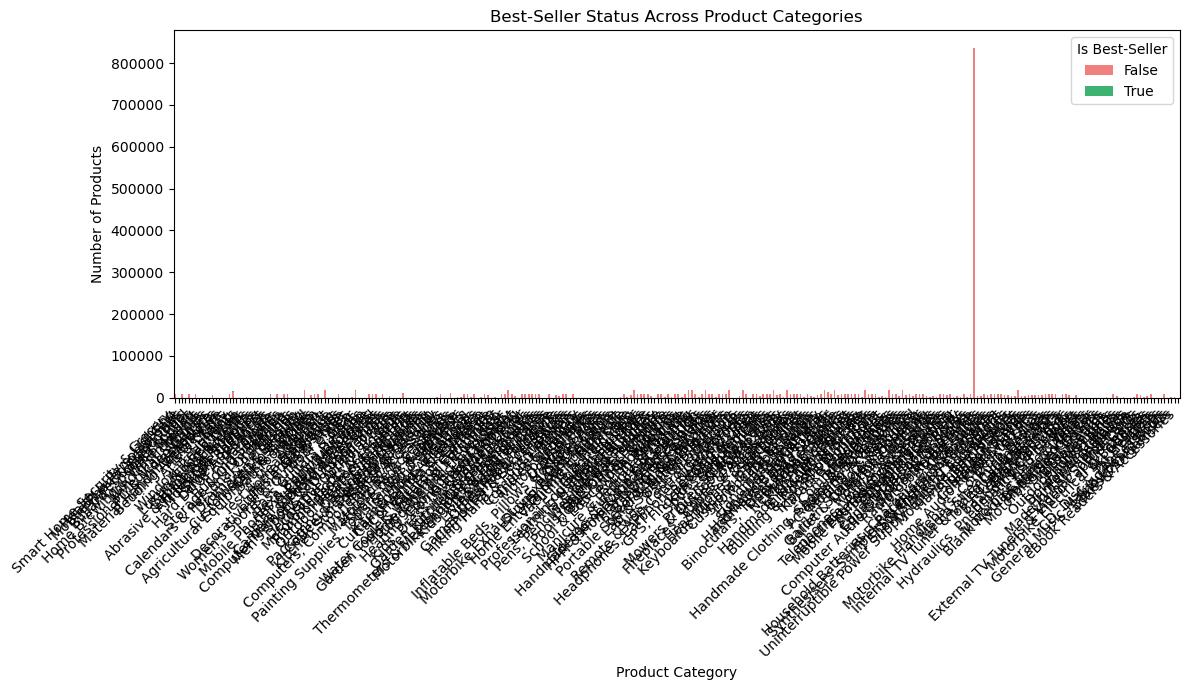

In [22]:
# Plot stacked bar chart
crosstab_plot.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 7),
    color=['lightcoral', 'mediumseagreen']  # False, True
)

plt.ylabel('Number of Products')
plt.xlabel('Product Category')
plt.title('Best-Seller Status Across Product Categories')
plt.legend(title='Is Best-Seller', loc='upper right')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [23]:
# Sort by ratio and take top 50 categories
top50_crosstab = crosstab.sort_values('best_seller_ratio', ascending=False).head(50)

# Drop the ratio column for plotting
top50_plot = top50_crosstab.drop(columns='best_seller_ratio')

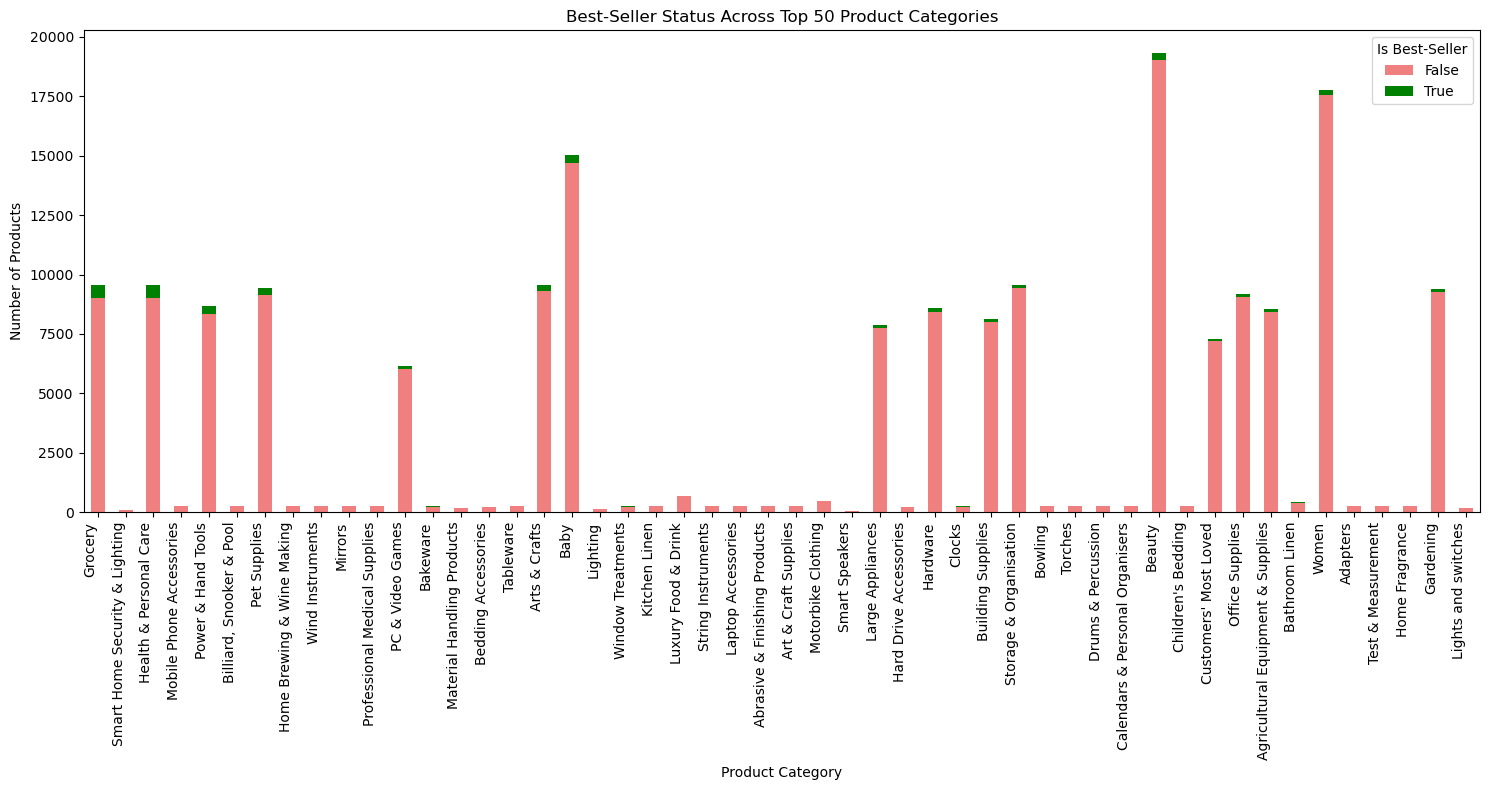

In [26]:
# Plot stacked bar chart
top50_plot.plot(
    kind='bar',
    stacked=True,
    figsize=(15, 8),
    color=['lightcoral', 'green']  # False, True
)

plt.ylabel('Number of Products')
plt.xlabel('Product Category')
plt.title('Best-Seller Status Across Top 50 Product Categories')
plt.legend(title='Is Best-Seller', loc='upper right')
plt.xticks(rotation=90, ha='right')
plt.tight_layout()
plt.show()

# Part 2: Exploring Product Prices and Ratings Across Categories and Brands
### Objective: Investigate how different product categories influence product prices.

## Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

## Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.

## Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.

## Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [27]:
# Calculate Q1 (25th percentile) and Q3 (75th percentile)
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

In [28]:
# Define lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [29]:
# Filter out outliers
df_clean = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print(f"Original dataset size: {len(df)}")
print(f"Dataset size after removing price outliers: {len(df_clean)}")

Original dataset size: 2443651
Dataset size after removing price outliers: 2115963


### Identify top 20 categories by count (for better plotting)

In [30]:
# Count products per category
top20_categories = df['category'].value_counts().head(20).index

In [31]:
# Filter dataset for top 20 categories
df_top20 = df[df['category'].isin(top20_categories)]

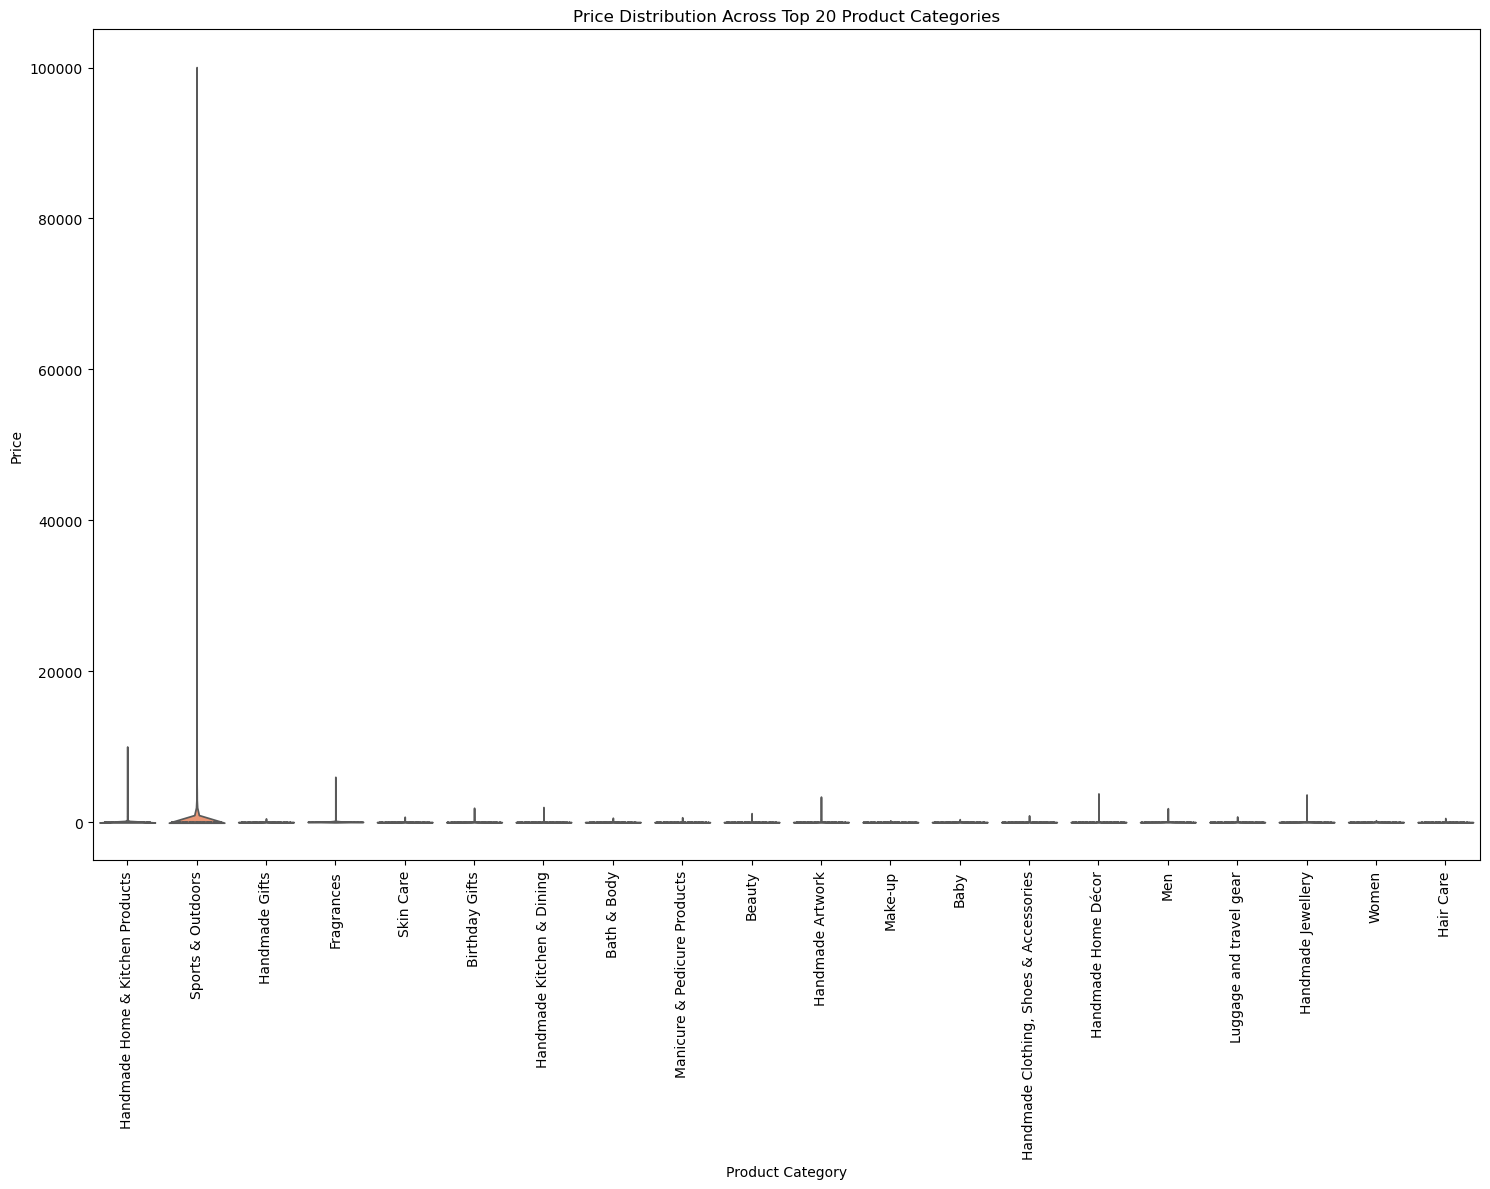

In [34]:
plt.figure(figsize=(15,12))

sns.violinplot(
    x='category',
    y='price',
    hue='category',         
    data=df_top20,
    inner='quartile',
    palette='Set2',
    legend=False            
)

plt.xticks(rotation=90)
plt.title('Price Distribution Across Top 20 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

### Find the category with the highest median price (using all categories)

In [35]:
median_prices = df.groupby('category')['price'].median().sort_values(ascending=False)
highest_median_category = median_prices.idxmax()
highest_median_value = median_prices.max()

print(f"The product category with the highest median price is '{highest_median_category}' with a median price of {highest_median_value}")


The product category with the highest median price is 'Laptops' with a median price of 1042.725


### Identify the top 10 categories by product count

In [36]:
top10_categories = df['category'].value_counts().head(10).index
df_top10 = df[df['category'].isin(top10_categories)]

In [37]:
avg_prices = df_top10.groupby('category')['price'].mean().sort_values(ascending=False)

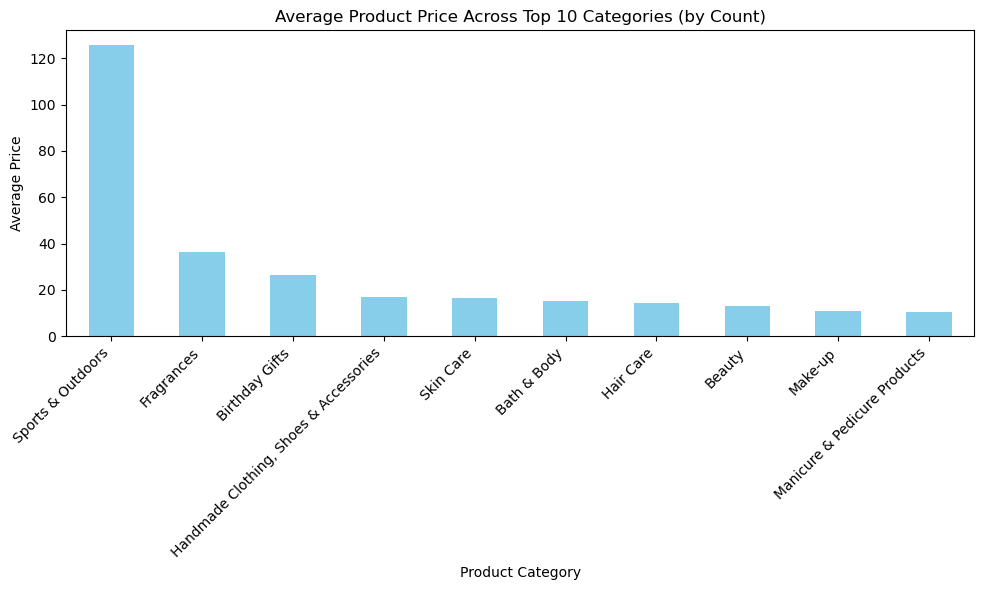

In [38]:
plt.figure(figsize=(10,6))
avg_prices.plot(kind='bar', color='skyblue')
plt.ylabel('Average Price')
plt.xlabel('Product Category')
plt.title('Average Product Price Across Top 10 Categories (by Count)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Identify the category with the highest average price

In [39]:
highest_avg_category = avg_prices.idxmax()
highest_avg_price = avg_prices.max()

print(f"The product category with the highest average price is '{highest_avg_category}' with an average price of {highest_avg_price:.2f}")


The product category with the highest average price is 'Sports & Outdoors' with an average price of 125.77


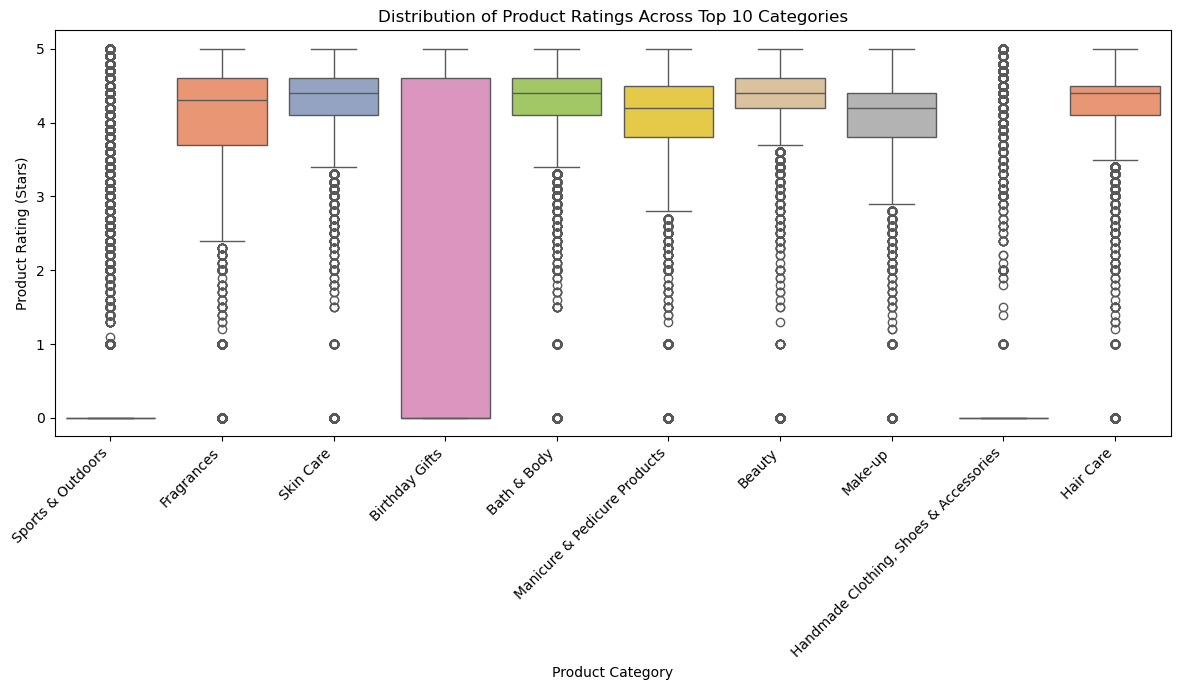

In [44]:
plt.figure(figsize=(12,7))
sns.boxplot(x='category', y='stars', hue='category', data=df_top10, palette='Set2', legend=False)
plt.xticks(rotation=45, ha='right')
plt.ylabel('Product Rating (Stars)')
plt.xlabel('Product Category')
plt.title('Distribution of Product Ratings Across Top 10 Categories')
plt.tight_layout()
plt.show()

# Part 3: Investigating the Interplay Between Product Prices and Ratings
### Objective: Analyze how product ratings (stars) correlate with product prices.

## Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?

## Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

In [45]:
from scipy.stats import pearsonr

In [46]:
# Ensure price and stars columns have numeric values
df = df.dropna(subset=['price', 'stars'])

In [47]:
corr_coef, p_value = pearsonr(df['price'], df['stars'])

print(f"Pearson correlation coefficient: {corr_coef:.3f}")
print(f"P-value: {p_value:.5f}")

Pearson correlation coefficient: -0.125
P-value: 0.00000


Correlation coefficient (corr_coef):

Positive → higher prices tend to have higher ratings

Negative → higher prices tend to have lower ratings

Close to 0 → no strong linear relationship

P-value:

< 0.05 → correlation is statistically significant

≥ 0.05 → correlation is not statistically significant

In [48]:
# Remove missing values
df_scatter = df.dropna(subset=['price', 'stars'])


In [ ]:
plt.figure(figsize=(10,6))

# Scatter plot
sns.scatterplot(
    x='price',
    y='stars',
    data=df_scatter,
    alpha=0.5,
    edgecolor=None  # Avoid warning with unfilled markers
)

# Regression line (without scatter points)
sns.regplot(
    x='price',
    y='stars',
    data=df_scatter,
    scatter=False,
    color='red',
    line_kws={'linewidth':2}
)

plt.title('Relationship Between Product Price and Rating')
plt.xlabel('Price')
plt.ylabel('Stars (Rating)')
plt.xscale('log')  # Optional: log scale for skewed prices
plt.tight_layout()
plt.show()

KeyboardInterrupt: 

In [50]:
# Select numeric columns
numeric_cols = df.select_dtypes(include='number')

In [51]:
# Compute correlation matrix
corr_matrix = numeric_cols.corr()

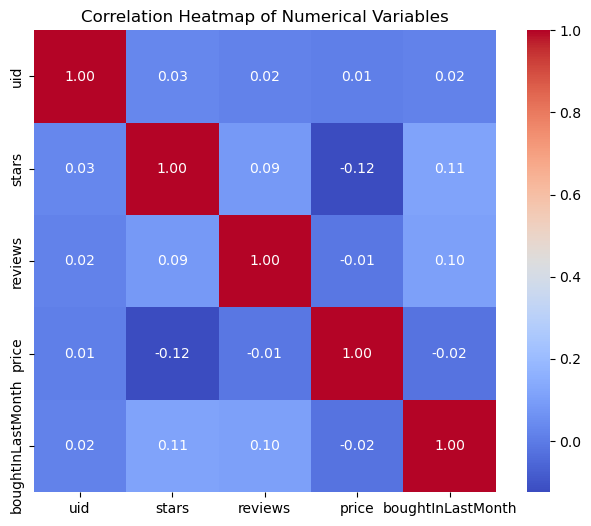

In [52]:
# Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

QQ Plot to Check if Price is Normally Distributed

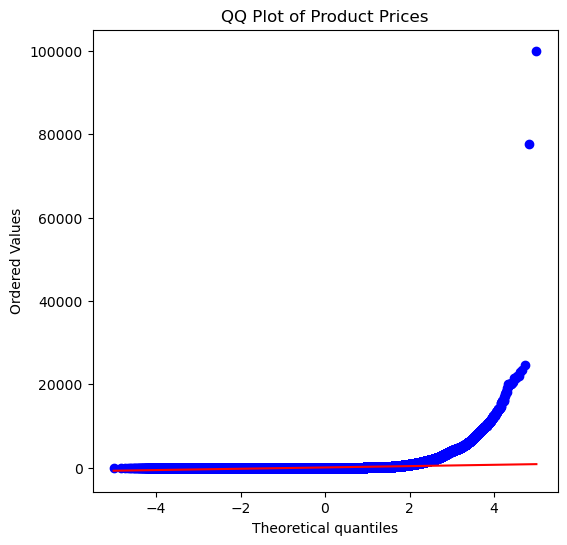

In [53]:
plt.figure(figsize=(6,6))
stats.probplot(df['price'].dropna(), dist="norm", plot=plt)
plt.title('QQ Plot of Product Prices')
plt.show()

# Bonus:

Do the same analysis without taking out the outliers. What are your insights?